# PHY 68 Project 4: Magnetic Oscillator

By: Shahd Ahmed, Zoe Sunenshine, Catelin Smith

For this project, we created an oscillator that consisted of two different balls -- one ping pong ball with magnetism and one red foam ball -- and attached it to a set of paper clips. This oscillator was swung from a regulated height both above a magnet placed in the center below it and without. We recorded the data to create a damped harmonic oscillator model and solved for the damping coefficient and the angular velocity to learn more about the impact that the magnet might have on our oscillator's motion and why. Finally, we examine the potential accuracy of our model.

Import necessary libraries:

In [1]:
import numpy as np
import pandas as pd

from scipy.integrate import odeint
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

# Plotting Packages
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mtick
import matplotlib.gridspec as gridspec
import matplotlib.animation as animation

# Statistical Packages
import statsmodels.api as sm
from scipy.interpolate import interp1d
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
import patsy as pt



### Classes

We created two different classes to aid in the modularity of our design: an animation class that reads the data from a given csv file and displays different videos and visual interpretations of our data and an integrator class that finds the best fit damping curve to our data and allows for error analysis

In [2]:
'''
Animation / Data Reading class
Reads in data from a csv file and contains animation functions
'''

class animateData:
    
    '''
    constructor function
    inputs: filename: name of the csv file
            scale: the ratio between meters in Tracker and meters in real life
            L: length of pendulum
            norm: determines if data needs to be normalized
    '''
    def __init__(self, filename = 0, scale=0, L=0, norm = 0):
        self.filename = filename
        self.scale = scale
        self.L = L
        self.norm = norm

    """
    function: LoadData
    purpose: Method reads in data guaged by tracker and converts 
            into numpy arrays
    inputs: n/a
    Return: the time in seconds and angular displacement in rad
    """
    def LoadData(self):
        data = pd.read_csv(self.filename, encoding="ISO-8859-1")
        data['x'] = np.arcsin(data['x'] * self.scale/self.L)
        self.x = data.iloc[0: 950]['x'][1:].to_numpy()
        if self.norm: self.x = (self.x-np.min(self.x))/(np.max(self.x)-np.min(self.x)) 
        self.t = data.iloc[0: 950]['t'][1:].to_numpy()
        shift = self.x[-1]
        for i in range(len(self.x)):
            self.x[i] = self.x[i] - self.x[-1]
        return self.t, self.x


    """
    function: oscillator_animation
    purpose: Method animates the angular velocity and displacement overtime
    inputs: t: time array
            theta: array containing angular displacement (in radians)
            theta_dot: array containing angular velocity (ω) 
            name: name of animation
    Return: nothing, but produces a video showing θ, ω over time
    """
    def oscillator_animation(self, t, theta, theta_dot, name):
        fig, ax = plt.subplots()
        self.theta = theta
        self.theta_dot = theta_dot
        self.name = name
        self.t = t
    
        theta_curve, = ax.plot(self.t, self.theta, 'r')
        theta_dot_curve, = ax.plot(self.t, self.theta_dot, 'b')
    
        ax.set_title('Simple Pendulum: Angular Position, Velocity vs Time')
        ax.set_xlim(0, self.t[-1])
        ax.set_ylim(-5, 5)
        ax.set_xlabel('Time (seconds)')
        ax.set_ylabel(r'$\theta$ (rad), $\dot \theta$ (rad/s)')
        ax.legend([r'$\theta$', r'$\dot \theta$'])
        ax.grid()
    
        def animate(i):
            theta_curve.set_data(self.t[:i+1], self.theta[:i+1])
            theta_dot_curve.set_data(self.t[:i+1], self.theta_dot[:i+1])
    
    
        ani= animation.FuncAnimation(fig, animate, frames=500)
        ffmpeg_writer = animation.FFMpegWriter(fps = 100)
        ani.save(self.name + '_position.mp4', writer=ffmpeg_writer)

        
    """
    function: phase_diagram
    purpose: Method animates the angular displacement and angular velocity 
            to help showing if the pendulum is underdamped or under 
            chaotic behaviour
    inputs: n/a
    Return: nothing, but produces a video showing θ vs. ω over time
    """
    
    def phase_diagram(self):
        # animate the phase diagram
        fig, ax = plt.subplots()
    
        phase_curve, = ax.plot(self.theta[0], self.theta_dot[0], 'b')
        phase_dot, =  ax.plot(self.theta[0], self.theta_dot[0], 'ro')
    
        ax.set_title('Simple Pendulum: Phase Diagram')
        ax.set_xlim(-1, 1)
        ax.set_ylim(-5, 5)
        ax.set_xlabel(r'$\theta$ (rad)')
        ax.set_ylabel(r'$\dot \theta$ (rad/s)')
        ax.grid()
    
        def animate(i):
            phase_curve.set_data(self.theta[:i+1], self.theta_dot[:i+1])
            phase_dot.set_data([self.theta[i]], [self.theta_dot[i]])
    
        ani= animation.FuncAnimation(fig, animate, frames=500)
        ffmpeg_writer = animation.FFMpegWriter(fps = 100)
        ani.save(self.name + "_phase.mp4", writer=ffmpeg_writer)
        

    """
    function: pendulum_sim
    purpose: Method animates the physical pendulum according to
            the angualar displacement over time
    inputs: n/a
    Return: nothing, but produces a video showing the swinging pendulum
    """   
    
    def pendulum_sim(self, L):
        def pend_pos(theta):
            return(L*np.sin(theta), -1*L*np.cos(theta))
    
    
        fig = plt.figure()
        ax = fig.add_subplot(aspect = 'equal')
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1.25, 0.25)
        ax.set_title('Swinging Pendulum Visualization')
        ax.grid()
    
        x0, y0 = pend_pos(self.theta[0])
        line, = ax.plot([0, x0], [0, y0], lw= 2, c='k')
        circle = ax.add_patch(plt.Circle(pend_pos(self.theta[0]), 0.05, fc = 'r', zorder=3))
    
        def animate(i):
            x, y = pend_pos(self.theta[i])
            line.set_data([0, x], [0, y])
            circle.set_center((x, y))
    
        ani= animation.FuncAnimation(fig, animate, frames=500)
        ffmpeg_writer = animation.FFMpegWriter(fps = 100)
        ani.save(self.name + '_pend.mp4', writer=ffmpeg_writer)


In [3]:
'''
Integrator class
Creates a best-fit damping harmonic oscillator curve from
the data and has plotting / analysis functions
'''

class integrator:
    def __init__(self, xdata, name, L):
        self.t = np.linspace(0, 20, 2000)
        self.xdata = xdata
        self.name = name
        self.L = L

        
    """
    function: oscillator
    purpose: Method returns the damped oscilliator ODE
    inputs: y: an array containing theta and omega values
            t: time array
            beta: the damping coefficient
            omega_0: the square of the oscillator's natural frequency
    Return: function (oscillator ODE)
    """
    def oscillator(self, y, t, beta, omega_0):
        theta, omega = y
        dydt = [omega, -2*beta*omega - (omega_0)*theta]
        return dydt
    
    
    """
    function: chaotic_oscillator
    purpose: Method returns the damped oscilliator ODE considering
    the driving force of magnetism
    inputs: y: an array containing theta and omega values
            t: time array
            beta: the damping coefficient
            omega_0: the square of the angular displacement
    Return: function (oscillator ODE)
    """
    
    def chaotic_oscillator(self, y, t, beta, omega_0):
        field = 1.01
        theta, omega = y
        dydt = [omega, -2*beta*omega - (omega_0)*theta + 0.01*omega*np.sin(theta)]
        return dydt 

    
    """
    function: ode_solver
    purpose: Method solves the ODE by taking initial from
            the collected data
    inputs: t: time array
            beta: damping coefficient
            omega_0: the square of the oscillator's natural frequency
    Return: theta values that fit the ODE
    """
    def ode_solver(self, t, beta, omega_0):
        y0 = [self.xdata[0], 0]
        sol = odeint(self.oscillator, y0, t, args=(beta, omega_0))
        return sol[:, 0]
    

    """
    function: chaos_ode_solver
    purpose: Method solves the ODE for choatic pendulum by taking initial from
            the collected data
    inputs: t: time array
            beta: damping coefficient
            omega_0: the square of the oscillator's natural frequency
    Return: theta values that fit the ODE
    """
    
    def chaos_ode_solver(self, t, beta, omega_0):
        y0 = [self.xdata[0], 0]
        sol = odeint(self.chaotic_oscillator, y0, t, args=(beta, omega_0))
        return sol[:, 0]
    
    
    
    """
    function: ode_solver_omega
    purpose: Method solves the ODE by taking initial from
            the collected data
    inputs: t: time array
            beta: damping coefficient
            omega_0: the square of the oscillator's natural frequency
    Return: omega values that fit the ODE
    """
    def ode_solver_omega(self, t, beta, omega_0):
        y0 = [self.xdata[0], 0]
        sol = odeint(self.oscillator, y0, t, args=(beta, omega_0))
        return sol[:, 1]
    
    """
    function: chaos_ode_solver_omega
    purpose: Method solves the ODE of chaotic pendulum by taking initial from
            the collected data
    inputs: t: time array
            beta: damping coefficient
            omega_0: the square of the oscillator's natural frequency
    Return: omega values that fit the ODE
    """
    
    def chaos_ode_solver_omega(self, t, beta, omega_0):
        y0 = [self.xdata[0], 0]
        sol = odeint(self.chaotic_oscillator, y0, t, args=(beta, omega_0))
        return sol[:, 1]

    
    """
    function: curve_fitter
    purpose: Method to find constant terms of the ODE by
            comparing the experimental data to the solution.
    inputs: t: time array
            name: animation name
            display: animation boolean (True if animation is desired)
            chaos: chaotic boolean (If True, model chaotic behavior)
    Return: nothing, but produces a graph of the data and the curve-fitted
            model as well as animations (if display = True)
    """
    
    def curve_fitter(self, t, xdata, name, display, chaos):
        plt.clf()
        
        # if we are modeling chaotic behavior, only consider
        # last few seconds of the model
        
        if chaos == True:
            t = t[140:]
            xdata = xdata[140:]
            self.xdata = xdata
            
        # plot the given data
        plt.plot(t, xdata, color='black', label = 'data')
        
        if chaos != True:
            # curve fits for the first 1 / shift_num of the points and plots
            # the shift is necessary to produce an accurate model, as seen by the
            # non-shifted graph
        
            shift_num = self.find_shift(t)
            shift = int(len(xdata) / shift_num) # shift index
            popt, pcov = curve_fit(self.ode_solver, t[:shift], xdata[:shift])
        
            # plot model
            self.ode_fit = self.ode_solver(t, popt[0], popt[1])
            self.ode_omega = self.ode_solver_omega(t, popt[0], popt[1])
            self.beta = popt[0]
            self.omega_0 = popt[1]
            plt.plot(t, self.ode_fit, label = 'Damped (first 1/' + str(shift_num) + '), β=' + "{:.3f}".format(popt[0]) + ',  ω0=' +"{:.3f}".format(np.sqrt(popt[1])))
            
            # curve fits for all of the points and plots
            popt2, pcov2 = curve_fit(self.ode_solver, t, xdata)
            plt.plot(t, self.ode_solver(t, popt2[0], popt2[1]), label = 'Damped (all points), β=' + "{:.3f}".format(popt2[0]) + ',  ω0=' +"{:.3f}".format(np.sqrt(popt2[1])))
        else: 
            # curve fits for all of the points and plots
            poptc, pcovc = curve_fit(self.chaos_ode_solver, t, xdata)
            plt.plot(t, self.chaos_ode_solver(t, poptc[0], poptc[1]), label = 'Damped (all points), β=' + "{:.3f}".format(poptc[0]) + ',  ω0=' +"{:.3f}".format(np.sqrt(poptc[1])))
        
        plt.xlabel('Time (s)')
        plt.ylabel('θ (Angular Displacement)')
        plt.legend()
        plt.title(self.name)
        
        if chaos == True:
            fig, ax = plt.subplots()
            ax.plot(self.chaos_ode_solver(t, poptc[0], poptc[1]), self.chaos_ode_solver_omega(t, poptc[0], poptc[1]), 'r')
            ax.legend(["Phase Diagram"])
            ax.set_title(self.name)
        
        # animates if desired
        if display == True:
            anim = animateData()
            anim.oscillator_animation(t, self.ode_fit, self.ode_omega, name)
            anim.phase_diagram()
            anim.pendulum_sim(1.2)
    
    
    
    """
    function: find_shift
    purpose: to find the shift value that maximizes the accuracy of the model
    inputs: t: time array
    Return: shift value
    """
    
    def find_shift(self, t):
        total_sum = 0
        fin_shift = 0
        
        # go through the data and curve fit using the first 1/(i/2) points,
        # starting with i = 2
        for i in range(2, 32):
            shift = int(len(self.xdata) / (i/2))
            popt, pcov = curve_fit(self.ode_solver, t[:shift], self.xdata[:shift])
            curr = 0
            
            # compute the difference between the data and the model and keep
            # the shift that minimizes the differences
            
            for j in range(len(t)):
                curr += abs(self.xdata[j] - self.ode_solver(t, popt[0], popt[1])[j])
                
            if (curr < total_sum) or (total_sum == 0):
                total_sum = curr
                fin_shift = i
        return fin_shift / 2
    
    
    """
    function: total_energy
    purpose: Method calculates the error by comparing the 
            total energy of the system with curve-fitted data 
            and non-curve-fitted data
    inputs: t: time array
            xdata: array of theta values from data
            crit: the time value where the period begins
                  flucuating abnormally
    Return: none, but creates two graphs (total energy and error)
    """
    
    def total_energy(self, t, xdata, crit):
        # potential and kinetic energy of model
        pe = (1/2)*(self.ode_omega**2)
        ke = (1/2)*(self.omega_0)*(self.ode_fit**2)
        
        # find rough omega using given data
        data_omega = np.diff(xdata) / np.diff(t)
        
        # potential and kinetic energy of data using
        # omega_0 value from model
        pe2 = (1/2)*(data_omega**2)
        ke2 = (1/2)*(self.omega_0)*(xdata[:-1]**2)


        #find error
        real = pe2+ke2
        exp = pe+ke
        #error = np.abs((real - exp[:-1])/real).mean()
        error_arr = ((real - exp[:-1])/real)*100
        
        # plot total energy of both model and data
        plt.plot(t[:-1], real, color = 'blue', label = 'Curve-fit Model')
        plt.plot(t, exp, color='red', label='Data')
        plt.legend()
        plt.xlabel('Time (s)')
        plt.ylabel('Total Energy (J)')
        plt.title(self.name + ': Total Energy (J) vs. Time (s) for Damped Oscillators')
        plt.show()
        
        # plot percent error
        plt.clf()
        plt.plot(t[:-1], error_arr)
        plt.xlabel('Time (s)')
        plt.ylabel('Percent Error between Energy of Model and Data')
        plt.axvline(x = crit, color = 'black', label = 't=' + "{:.3f}".format(crit))
        plt.legend()
        plt.title(self.name + ': Percent Error between Energy of Model and Data over Time')
        plt.show()
        
        plt.clf()
        plt.plot(t[:20], error_arr[:20])
        plt.xlabel('Time (s)')
        plt.ylabel('Percent Error')
        plt.title(self.name + ': Percent Error for first 20 points')
        plt.show()
        
    """
    function: plot_error
    purpose: Method calculates and plots the error of the model vs. data
    inputs: t: time array
            xdata: array of theta values from data
            crit: the time value where the period begins
                  flucuating abnormally
            index: the index at which the critical time occurs
    Return: none, but creates two graphs (data with model and error)
    """
        
    def plot_error(self, t, xdata, crit, index):
        # plot model and data
        plt.clf()
        plt.plot(t, self.ode_fit)
        plt.plot(t, xdata)
        plt.xlabel('Time (s)')
        plt.ylabel('θ (angular displacement, radians)')
        plt.title(self.name + ': Angular Displacement (Radians) vs. Time (s)')
        plt.show()
        
        # plot percent error of model
        plt.clf()
        model_error = ((xdata - self.ode_fit[:len(xdata)])/xdata)
        plt.plot(t, model_error)
        plt.xlabel('Time (s)')
        plt.ylabel('Percent Error between Model and Data')
        plt.axvline(x = crit, color = 'black', label = 't=' + "{:.3f}".format(crit))
        plt.legend()
        plt.title(self.name + ': Percent Error between Model and Data over Time')
        plt.show()
        
        plt.clf()
        plt.plot(t[:index], model_error[:index])
        plt.xlabel('Time (s)')
        plt.ylabel('Percent Error between Model and Data')
        plt.title(self.name + ': Percent Error over Time for first ' + str(index) + ' points')
        plt.show()


### Data Analysis: Curve-Fitting and Visualizing Models

Now, we will begin by finding the best-fit damping harmonic oscillator model and graphing it along with its data points. The beta value / damping coefficient will be displayed in the legend of the graphs. Beneath each graph can be seen the three different types of model videos: a standard video that shows the model over time with theta and omega, a phase diagram video that shows theta vs. omega, and a video showing what this model would look like with a pendulum in real life.

First we will begin by examining the ping-pong ball that contained no magnets inside of it oscillating over a magnet and not.

#### Empty Ping-Pong Ball Oscillator

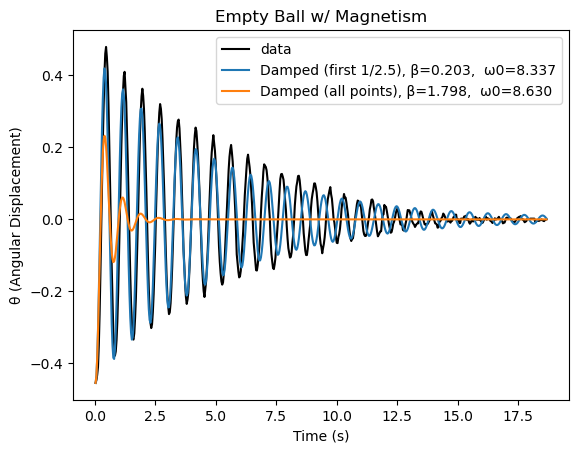

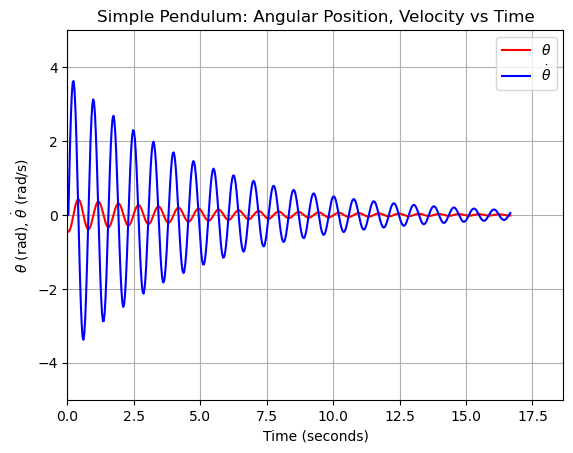

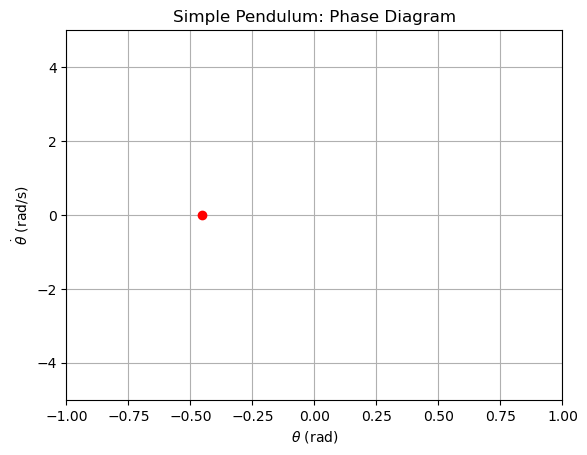

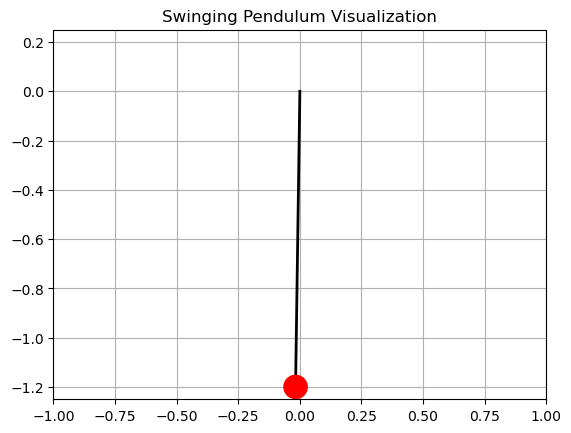

In [4]:
scale = 3/250
empty_ball = animateData("EMPTY BALL w magnetism.csv", scale, 12)
empty_ball.LoadData()

empty_integrate = integrator(empty_ball.x, 'Empty Ball w/ Magnetism', 12)
empty_integrate.curve_fitter(empty_ball.t, empty_ball.x, 'empty_mag_position', True, False)


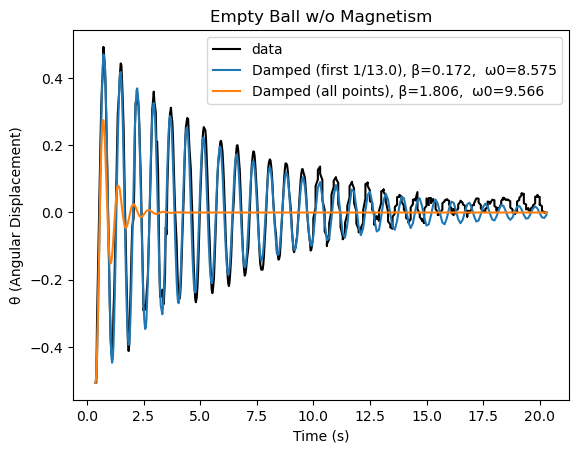

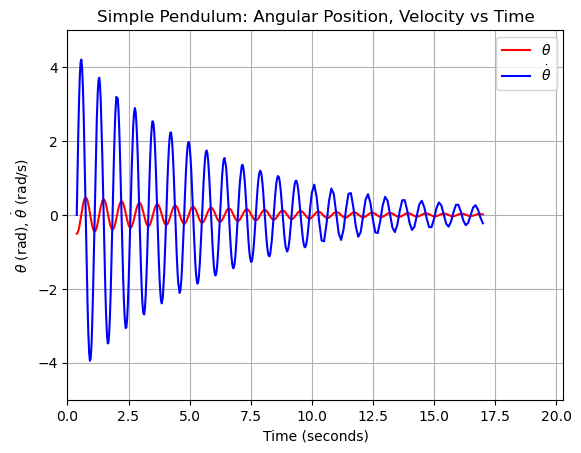

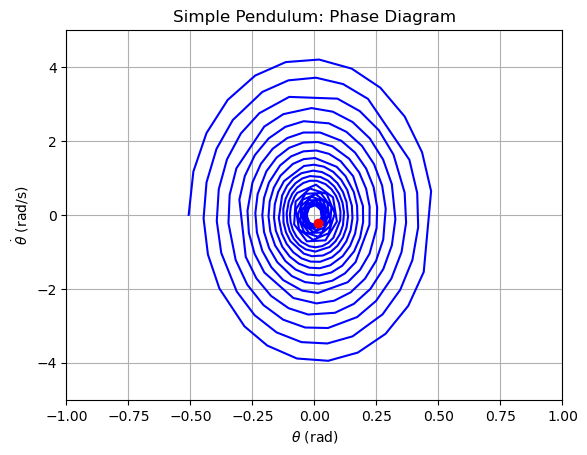

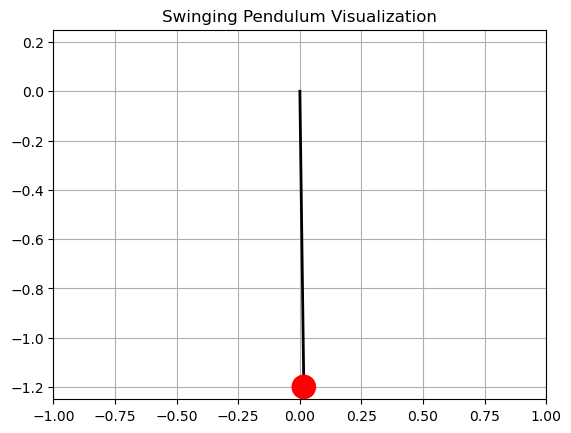

In [5]:
WhiteE = animateData("EmptyWhiteNoMag.csv", 4/100, 12, 1)
WhiteE.LoadData()

WhiteE_integrate = integrator(WhiteE.x, 'Empty Ball w/o Magnetism', 12)
WhiteE_integrate.curve_fitter(WhiteE.t, WhiteE.x, 'empty_mag_position', True, False)

As we can see, the damping coefficient for the oscillator without magnetism is smaller than the damping coefficient with magnetism (without magnetism, β = .172, but with magnetism, β = .203). The smaller the damping coefficient, the more similar the oscillator is to a simple harmonic oscillator, and since in both cases, β < ω0, both oscillators are underdamped, which is seen from its oscillatory behavior. 

The damping coefficient for the oscillator without magnetism is likely the result of air / the drag force slowing down the ping-pong ball over time, which would also contribute to some of the damping coefficient for the oscillator with magnetism. Since the only difference between the two models is that the former has magnetism, this magnetism most likely contributes to the former's higher damping coefficient. 

Now, let us examine the other models and see if a similar instance occurs.

#### Red Foam Ball Oscillator

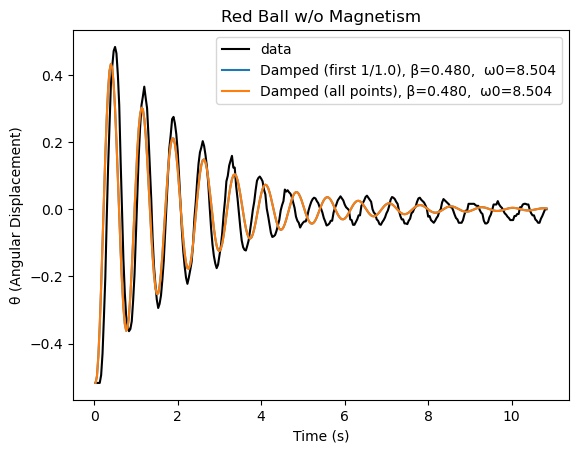

In [6]:
Red = animateData("RED BALL (no magnetism).csv", 3.2/250, 12, 1)
Red.LoadData()

Red_integrate = integrator(Red.x, 'Red Ball w/o Magnetism', 12)
Red_integrate.curve_fitter(Red.t, Red.x, 'red_nomag_position', False, False)

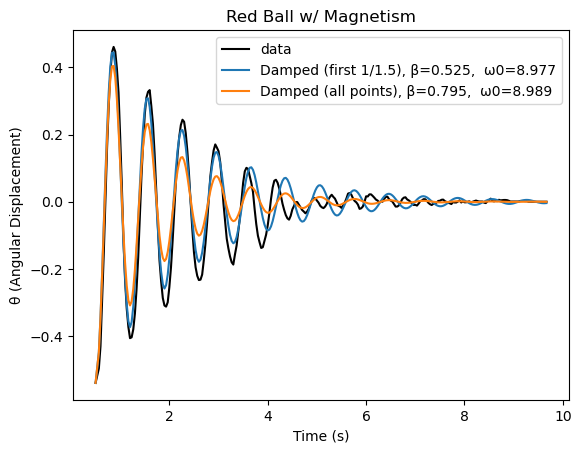

In [7]:
MagRed = animateData("RED BALL W MAGNETISM.csv", 3.5/250, 12, 1)
MagRed.LoadData()

MagRed_integrate = integrator(MagRed.x, 'Red Ball w/ Magnetism', 12)
MagRed_integrate.curve_fitter(MagRed.t, MagRed.x, 'red_mag_position', False, False)

As we can see in the graph above, a similar thing occured: the damping coefficient of the oscillator with magnetism is greater than the coefficient of the one without since without magnetism, β = 0.48, but with magnetism, β = 0.525. These oscillators are again underdamped since β < ω0, and their underdamped behavior can also be seen in their phase diagram videos.

It is interesting to note in general the difference between these graphs and the previous ones; since the red ball is made out of foam, while it has the same surface area as the ping-pong ball, it is less dense and thus has less mass, which could result in its periods being larger and it having a higher damping coefficient in general.

However, it is also clear from simply looking at the graphs that our "best-fit" models are not the most accurate fit for our data. There are several reasons why this could be true, such as our algorithm being faulty, but there are two options that we will investigate: magnetism causing some deviation in the magnetic oscillators and human error in data collection for all oscillators

### Analyzing Deviation from Damping Harmonic Oscillator Model

#### 1) Magnetism

A hypothesis we had was that the closer the oscillator got to the magnet, the more the period increased in a way that was outside of the scope of a damping harmonic oscillator due to its magnetic force. Additionally, if the oscillator got close enough to the magnet, it appeared that the amplitude would suddenly decrease significantly, as seen by the red foam ball oscillator. We can test this hypothesis by studying the period of the magnetic oscillators.

In [8]:
"""
function: oscillation
purpose: Method calculates and plots the period as a function of time
         to evaluate whena and how the model starts to deviate 
inputs:
        y: array of theta 
        t: time interval
        plotter: boolean to determine whether to graph the data or not
        critical: boolean to check for the peaks
Return: 
        critical time: array of time stamps showing when the peaks are happening
        crititcal_index: array of indicies of each peak
"""

def oscillation(y, t, name, plotter, critical):

    # Find peaks to measure the damped period
    local_maxima = []
    indices = []

    for i in range(1, len(t)-1):
        if (y[i] > y[i - 1]) and (y[i] >= y[i + 1]):
            local_maxima.append(y[i])
            indices.append(i)

    # Calculate the periods between consecutive peaks
    peak_times = t[indices]
    peak_amplitudes = y[indices]
    periods = np.diff(peak_times)

    if plotter == True:
        # Plot the oscillation and mark the peaks
        plt.clf()
        plt.plot(peak_times[1:], periods)
        plt.xlabel('Time (s)')
        plt.ylabel('Period (s)')
        plt.title(name + ': Oscillation Period (s) vs. Time (s)')
        plt.show()

        plt.clf()
        plt.plot(peak_amplitudes[1:], periods)
        plt.xlabel('θ (angular displacement, radians)')
        plt.ylabel('Period (s)')
        plt.title(name + ': Oscillation Period (s) vs. Angular Displacement (Radians)')
        plt.show()


        # Print the estimated periods
        print("Mean estimated damped period:", np.mean(periods))
        
        return periods, peak_times, peak_amplitudes
        
    if critical == True:
        critical_point = 0
        critical_time = 0
        critical_y = 0
        critical_index = 0

        for i in range(len(periods)-1):
            if (periods[i] - periods[i+1]) > .1:
                critical_point = periods[i] - periods[i+1]
                critical_time = peak_times[i+1]
                critical_y = local_maxima[i+1]
                critical_index = i+1
                break
        
        plt.clf()
        plt.figure(figsize=(10, 6))
        plt.plot(t, y, label='Damped Oscillation')
        plt.axvline(x = critical_time, color = 'b', label = 't=' + "{:.3f}".format(critical_time) + ', θ='+ "{:.3f}".format(critical_y))
        plt.plot(peak_times, y[indices], 'ro', label='Peaks')
        plt.xlabel('Time (s)')
        plt.ylabel('Theta (angular displacement)')
        plt.title(name + ': Damped Oscillation with Magnetic Damping')
        plt.legend()
        plt.show()
    
        return critical_time, critical_index
        
        
"""
function: frequency
purpose: Method calculates and plots the frequency values as
         a funciton of time
inputs:
        periods: array of period values 
        peak_times: array of where the peaks occur
        peak_amplitudes: array of theta values
Return: 
        nothing but plots the frequency
"""        
  
        
def frequency(periods, peak_times, peak_amplitudes):
    # Calculate frequency from the periods
    frequencies = 1 / periods

    # Plot frequency over time
    plt.figure(figsize=(10, 6))
    plt.plot(peak_times[1:], frequencies, 'o-', label='Frequency')
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Frequency Over Time')
    plt.show()

    # Plot frequency as a function of angular displacement
    plt.figure(figsize=(10, 6))
    plt.plot(peak_amplitudes[1:], frequencies, 'o-', label='Frequency')
    plt.xlabel('Angular Displacement (rad)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Frequency vs. Angular Displacement')
    plt.show()

    # Output the calculated frequencies and mean frequency
    #print("Calculated frequencies between peaks:", frequencies)
    print("Mean calculated frequency:", np.mean(frequencies))

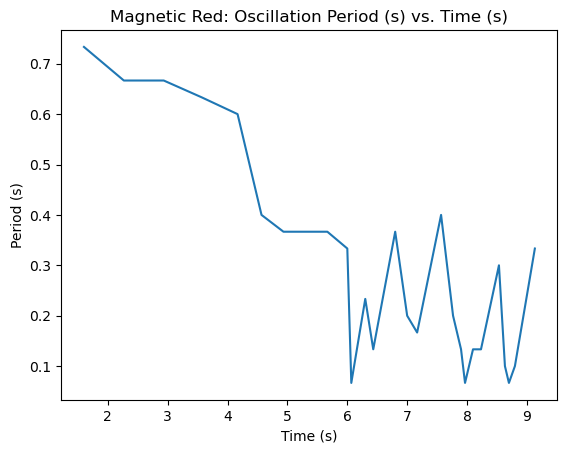

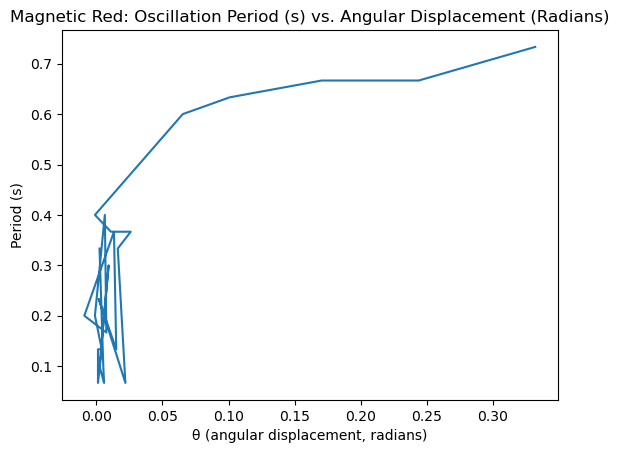

Mean estimated damped period: 0.3061728394925926


In [9]:
mag_red_periodic, mag_red_times, mag_red_amp = oscillation(MagRed.x, MagRed.t, 'Magnetic Red', True, False)

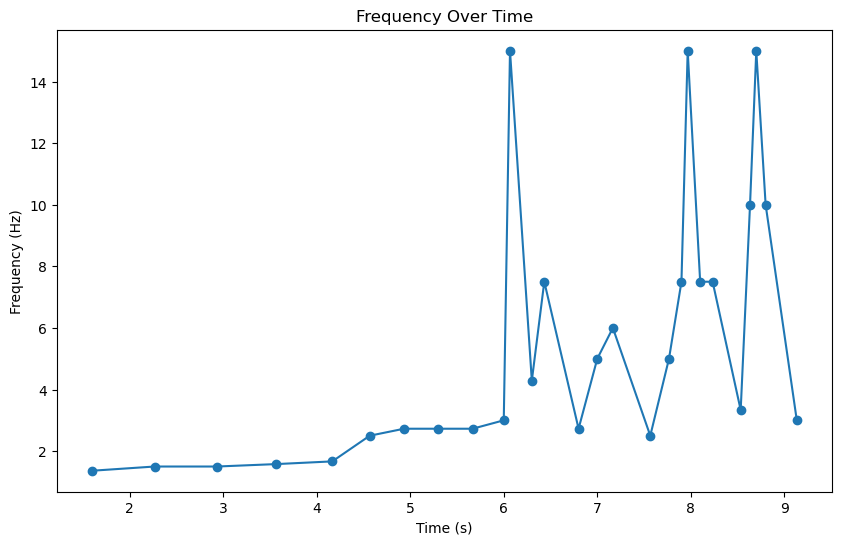

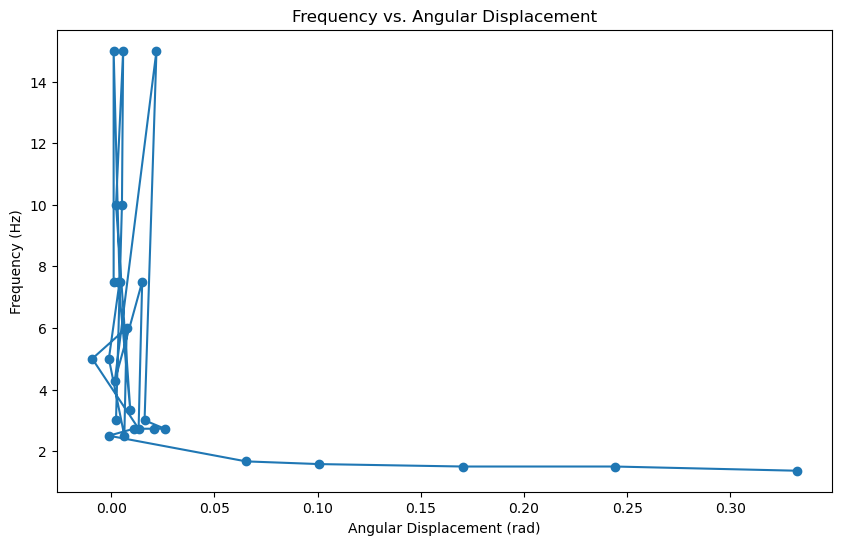

Mean calculated frequency: 5.48656995457984


In [10]:
frequency(mag_red_periodic, mag_red_times, mag_red_amp)

The period and frequency tend to be fairly stable until around 4 - 6s, so let us write some code that displays the first instance where the period increases by more than 0.1s. If magnetism is playing a roll in this, that should show us around what angular displacement the center magnet starts influencing the oscillator more and breaks it out of its previous damping harmonic oscillation pattern.

<Figure size 640x480 with 0 Axes>

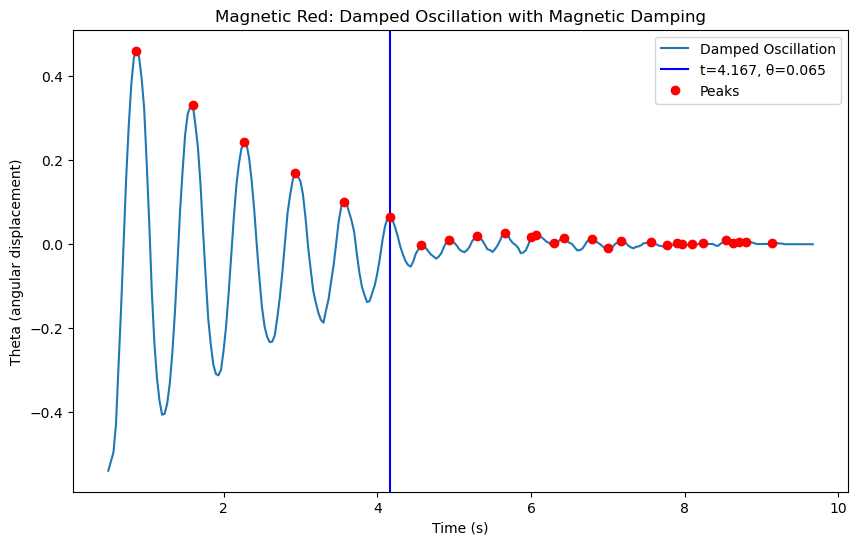

In [11]:
red_crit_time, red_index = oscillation(MagRed.x, MagRed.t, 'Magnetic Red', False, True)

So it appears that around t = 4.2 s at θ = ~.07, the oscillator has become too close to the magnet, so the magnetic force takes over the graviational force, causing the oscillator to lose some of its previous characteristics, such as its amplitude and period.

If we analyze the white ping-pong oscillator, we see that something very similar occurs:

<Figure size 640x480 with 0 Axes>

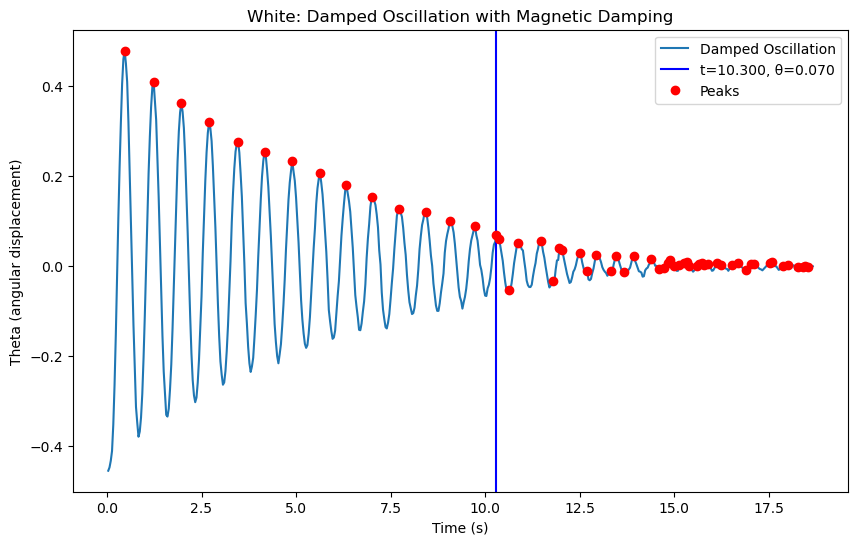

In [12]:
plt.clf()
white_crit_time, white_index = oscillation(empty_ball.x, empty_ball.t, 'White', False, True)

Since θ = 0.07, the confirms our hypothesis that at around 0.07 radians, the magnetism becomes too much for the oscillator, thereby causing it to deviate from its previous behavior; the magnet starts to pull it in more than just a damping harmonic oscillator, which is why our model tends to look more inaccurate towards the second half.

#### 2) Human Error:

To investigate the impact human error might have on our model, we can look at the differences between our model and our data and also look at the total energy of our model and our data


##### Total Energy

Below is the graph for total energy for data and the model -- even if the model isn't accurate, the data should follow a similar shape, so those spikes could be due to human error (especially since the model follows pretty close to the data in the beginning, so even if the data did not follow a damping oscillator perfectly, it should still look a little like one in the beginning)

/var/folders/sc/bnmk3_yx3kjggn68c5zy2rb40000gn/T/ipykernel_8212/3818030173.py:240: RuntimeWarning: divide by zero encountered in divide
  error_arr = ((real - exp[:-1])/real)*100


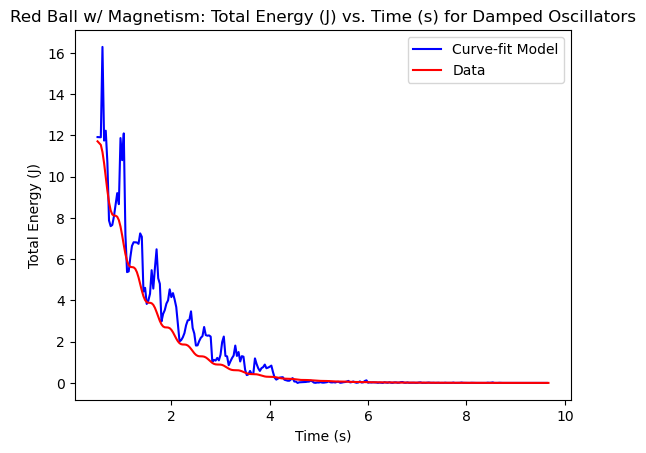

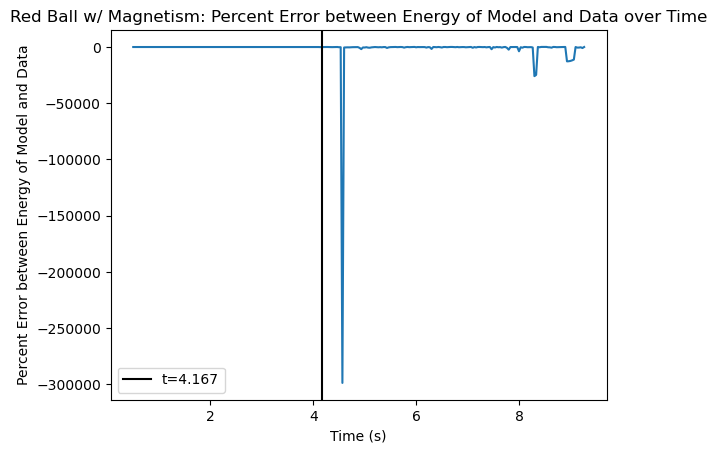

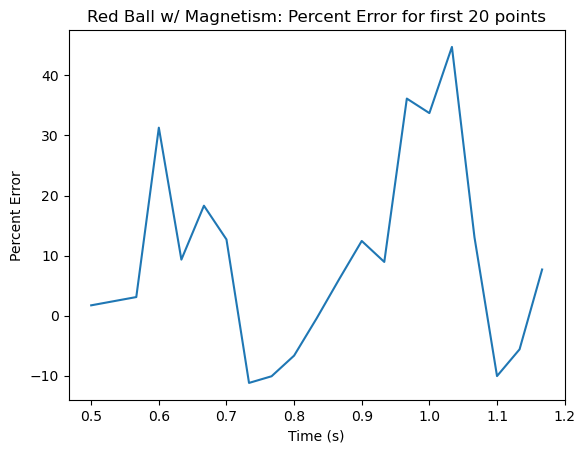

In [13]:
MagRed_integrate.total_energy(MagRed.t, MagRed.x, red_crit_time)

We see that the error overall is not too terrible except for that one point around 4.5 seconds, which is most likely due to the fact that the total energy is near zero at that point, so any small fluctuations will create a very large percentage of difference, but even just examining the first 20 points, we can see that there is a significant amount of error

Now, let us examine what is arguably more important: the error for angular displacement, or θ

##### θ Model vs. Data

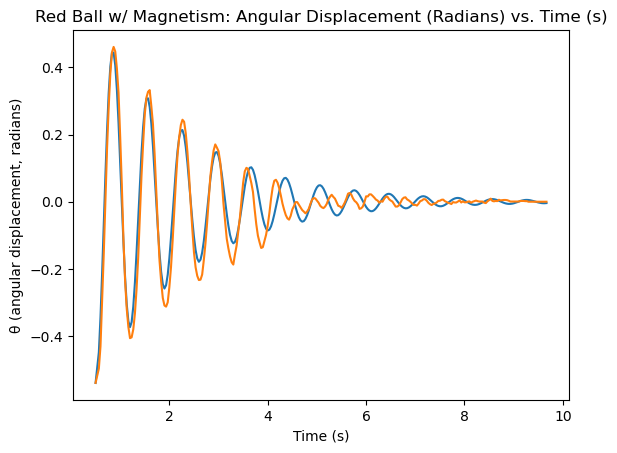

/var/folders/sc/bnmk3_yx3kjggn68c5zy2rb40000gn/T/ipykernel_8212/3818030173.py:291: RuntimeWarning: divide by zero encountered in divide
  model_error = ((xdata - self.ode_fit[:len(xdata)])/xdata)


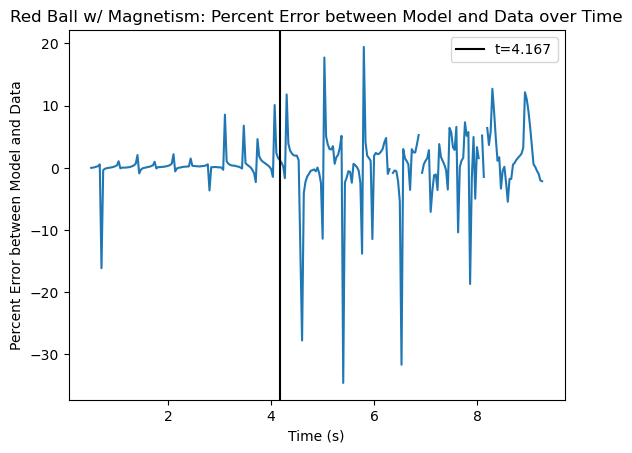

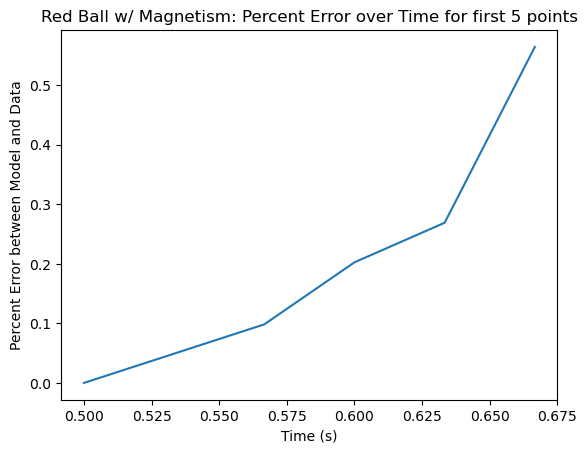

In [14]:
MagRed_integrate.plot_error(MagRed.t, MagRed.x, red_crit_time, red_index)

We can see that there are almost oscillatory spikes occuring in the data that seem to occur where the data and the model approach zero, which would again cause a large percentage of difference since the numbers are so small. Outside of that, the model seems to be within a 20% error, some of which could be human, before reaching the point where the magnet begins to influence the oscillator significantly more. After that point, the error increases dramatically, which also seems to confirm that while our model can fit decently enough to the data before that point, after that point, the magnetism has too much of an influence on the oscillator's motion.

We can try to analyze this motion as chaotic behavior.

### Chaotic Behavior of Late-Stage Pendulum

Pendulum exhibits chaotic behavior due to the magnetic force of the bar magnets. The chaotic behavior is more noticeble towards the end of oscillation because the bar magnets have stronger impact on the pendulum than gravity. The pendulum was modeled during the last five seconds before it reached equlibrium. 

Now, the magnetism is a constant driving force. With slight variations in position each time the pendulum crosses the magnets, each magnet contributes differenly depending on how close the pendulum is to each magnet. The different position result

Thus, the phase diagram demonstrates less correlation to the spiral plot of damped oscillation which can be interpreted as a result of the chaotic behavior.

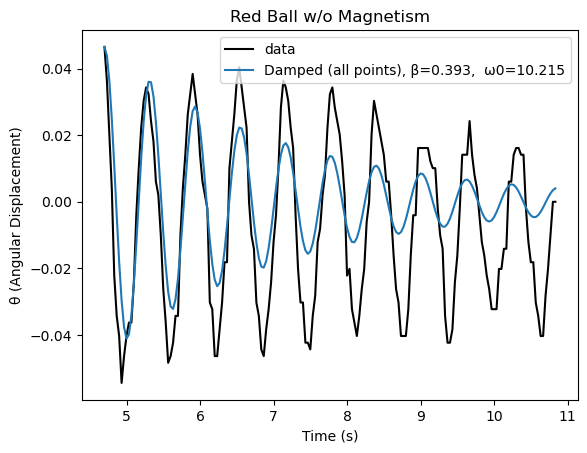

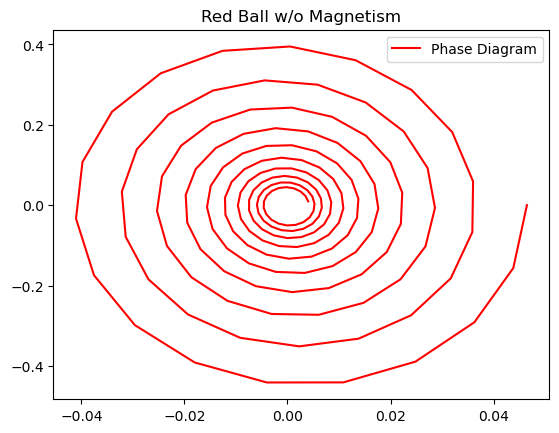

In [15]:
Red_integrate.curve_fitter(Red.t, Red.x,'red_nomag', False, True)

/Users/catelinsmith/anaconda3/lib/python3.11/site-packages/scipy/integrate/_odepack_py.py:248: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  warnings.warn(warning_msg, ODEintWarning)


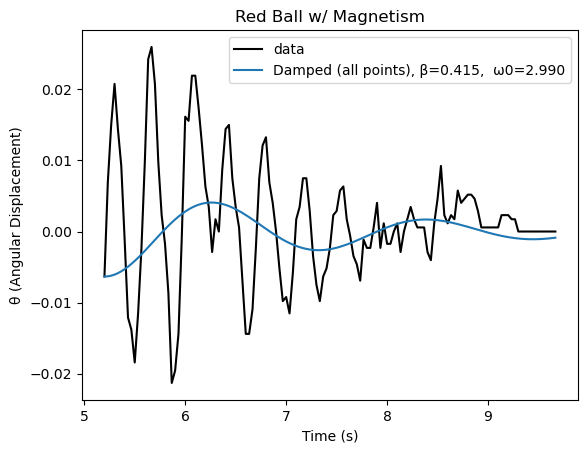

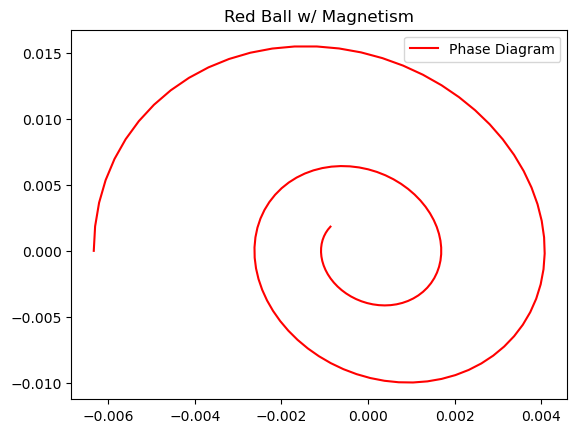

In [16]:
MagRed_integrate.curve_fitter(MagRed.t, MagRed.x, 'red_mag', False, True)

We had originally created a bifurcation graph, but we were unable to transfer the code to this notebook without errors. We have the graph on our presentation slides and have placed it in the zip file. The positions of the bifurcation indicates that chaos is present in the phase diagrams. Specifically that the spiral is unstable and has an equilibrium point.

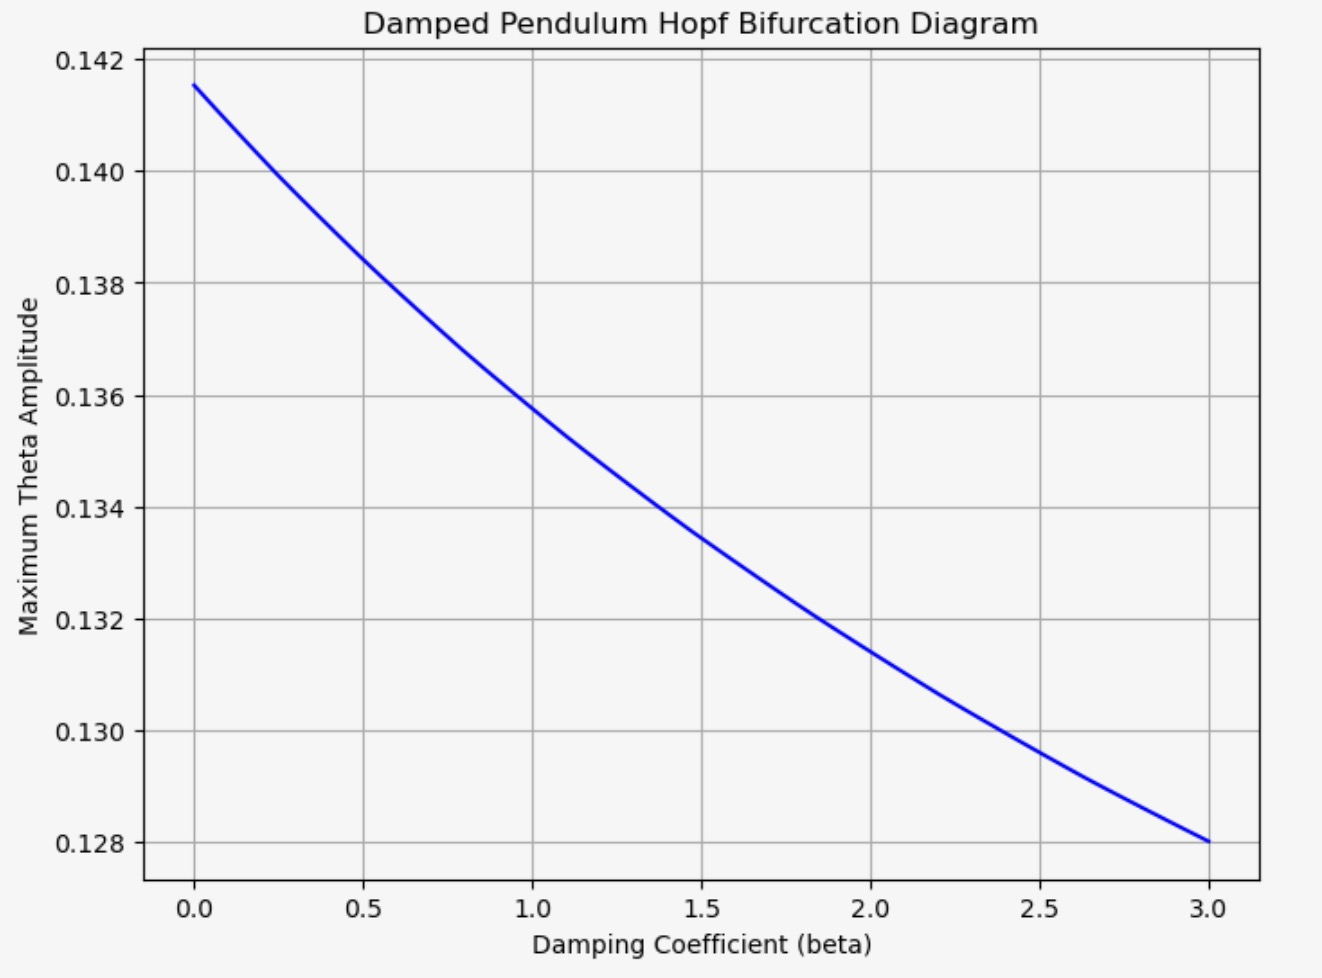